# Examen práctico de Estadística Descriptiva (EA2)
## Matrícula de Educación Superior, Región de Tarapacá (2021)

**Tema:** correlación y regresión (Ítem 1) · modalidad y probabilidades (Ítem 2)

## 0. Configuración

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

# Configuración visual y de presentación
pd.set_option('display.float_format', lambda x: f'{x:,.3f}')
sns.set_theme(style='whitegrid')

## 1. Datos, población y variables

Se trabaja con el archivo `02_MATRICULAS_ED_SUPERIOR_TARAPACA_2021.xlsx`, que contiene **15.459 registros y 28 variables** sobre matrícula de educación superior en la Región de Tarapacá para 2021. La población de interés son los estudiantes matriculados en instituciones de educación superior de esa región durante ese año; el análisis describe los registros disponibles en la base y no presupone que sean una muestra aleatoria.

**Unidad de observación:** cada fila se interpreta como un registro de matrícula asociado a una carrera e institución. Por ello, el número de filas no se debe interpretar automáticamente como el número de personas únicas.

**Variables:** la base reúne características de los estudiantes y sus matrículas (por ejemplo, género, edad y año de ingreso), datos de institución y carrera (tipo, nivel, área, modalidad, jornada y duración), y montos de matrícula y arancel. El diccionario de la sección 1.1 identifica las variables utilizadas y su tipo.

**Alcance:** el año 2021 corresponde al período de la base. `AÑO INGRESO` indica cuándo ingresó el estudiante a la carrera, por lo que sus valores pueden ser anteriores a 2021; no representa una serie anual de matrículas nuevas.

In [2]:
baseDatos = "02_MATRICULAS_ED_SUPERIOR_TARAPACA_2021.xlsx"
df = pd.read_excel(baseDatos)

print(f'Cantidad de registros: {df.shape[0]:,}')
print(f'Cantidad de variables: {df.shape[1]}')
display(df.head())
df.info()

Cantidad de registros: 15,459
Cantidad de variables: 28


,ID,GENERO,EDAD,RANGO EDAD,AÑO INGRESO,SEMESTRE INGRESO,TIPO DE INSTITUCION,NOMBRE DE INSTITUCION,ACREDITACION INSTITUCIONAL,PERIODO DE ACREDITACION,...,NIVEL CARRERA,AREA CONOCIMIENTO,DURACION PLAN DE ESTUDIO (SEMESTRES),DURACION PROCESO TITULACION (SEMESTRES),DURACION TOTAL CARRERA (SEMESTRES),VALOR MATRICULA (PESOS),VALOR ARANCEL (PESOS),REGION SEDE,PROVINCIA SEDE,COMUNA SEDE
0,250,Femenino,27,25 a 29,2012,Primer semestre,Universidades CRUCH,UNIVERSIDAD ARTURO PRAT,ACREDITADA,21/12/2017 AL 21/12/2021,...,Carreras Profesionales,Derecho,10,0,10,161000,2898000,Tarapaca,Iquique,Iquique
1,257,Femenino,24,20 a 24,2021,Primer semestre,Universidades CRUCH,UNIVERSIDAD ARTURO PRAT,ACREDITADA,21/12/2017 AL 21/12/2021,...,Carreras Profesionales,Administracion y Comercio,10,0,10,173000,2797000,Tarapaca,Iquique,Iquique
2,430,Masculino,19,15 a 19,2021,Primer semestre,Institutos Profesionales,IP INACAP,ACREDITADA,11/12/2016 AL 11/12/2022,...,Carreras Profesionales,Tecnologia,8,0,8,250000,2426000,Tarapaca,Iquique,Iquique
3,657,Femenino,33,30 a 34,2020,Primer semestre,Universidades Privadas,UNIVERSIDAD SANTO TOMAS,ACREDITADA,31/03/2021 AL 31/03/2025,...,Carreras Profesionales,Derecho,11,1,12,105000,3275000,Tarapaca,Iquique,Iquique
4,801,Masculino,34,30 a 34,2005,Primer semestre,Universidades CRUCH,UNIVERSIDAD ARTURO PRAT,ACREDITADA,21/12/2017 AL 21/12/2021,...,Carreras Profesionales,Derecho,10,0,10,161000,2898000,Tarapaca,Iquique,Iquique


<class 'pandas.DataFrame'>
RangeIndex: 15459 entries, 0 to 15458
Data columns (total 28 columns):
 #   Column                                   Non-Null Count  Dtype  
---  ------                                   --------------  -----  
 0   ID                                       15459 non-null  int64  
 1   GENERO                                   15459 non-null  str    
 2   EDAD                                     15459 non-null  int64  
 3   RANGO EDAD                               15459 non-null  str    
 4   AÑO INGRESO                              15459 non-null  int64  
 5   SEMESTRE INGRESO                         15459 non-null  str    
 6   TIPO DE INSTITUCION                      15459 non-null  str    
 7   NOMBRE DE INSTITUCION                    15459 non-null  str    
 8   ACREDITACION INSTITUCIONAL               15459 non-null  str    
 9   PERIODO DE ACREDITACION                  14066 non-null  str    
 10  AÑOS DE ACREDITACION                     14066 non-null  

### 1.1 Diccionario de variables utilizadas

| Variable | Tipo | Escala | Uso en el trabajo |
|---|---|---|---|
| `VALOR MATRICULA (PESOS)` | Cuantitativa continua | Razón | Ítem 1.1 |
| `VALOR ARANCEL (PESOS)` | Cuantitativa continua | Razón | Ítem 1.1, 1.2 |
| `DURACION TOTAL CARRERA (SEMESTRES)` | Cuantitativa discreta | Razón | Ítem 1.2 |
| `DURACION PLAN DE ESTUDIO (SEMESTRES)` | Cuantitativa discreta | Razón | _opcional_ |
| `TIPO DE INSTITUCION` | Cualitativa nominal | Nominal | Ítem 1.1, 2.2 |
| `AREA CONOCIMIENTO` | Cualitativa nominal | Nominal | Ítem 1.2, 2.3 |
| `MODALIDAD` | Cualitativa nominal | Nominal | Ítem 2.1, 2.2 |
| `JORNADA` | Cualitativa nominal | Nominal | Ítem 2.1 (apoyo) |
| `AÑO INGRESO` | Cuantitativa discreta | Intervalo | Ítem 2.1 |
| `GENERO` | Cualitativa nominal | Nominal | Ítem 2.3 |
| `NIVEL CARRERA` / `NIVEL DE ESTUDIO CARRERA` | Cualitativa ordinal | Ordinal | Filtros |

### 1.2 Calidad de datos

In [3]:
# Verificar que existan todas las columnas clave
cols = [
    "VALOR MATRICULA (PESOS)", "VALOR ARANCEL (PESOS)",
    "DURACION TOTAL CARRERA (SEMESTRES)", "TIPO DE INSTITUCION",
    "AREA CONOCIMIENTO", "MODALIDAD", "JORNADA",
    "NIVEL DE ESTUDIO CARRERA", "AÑO INGRESO", "GENERO"
]
columnas_faltantes = [col for col in cols if col not in df.columns]
print('Columnas faltantes:', columnas_faltantes)

# Revisar valores nulos y duplicados
print('Valores nulos en variables de interés:')
display(df[cols].isna().sum().to_frame('Valores nulos'))
print(f'Registros duplicados completos: {df.duplicated().sum()}')

Columnas faltantes: []
Valores nulos en variables de interés:


,Valores nulos
VALOR MATRICULA (PESOS),0
VALOR ARANCEL (PESOS),0
DURACION TOTAL CARRERA (SEMESTRES),0
TIPO DE INSTITUCION,0
AREA CONOCIMIENTO,0
MODALIDAD,0
JORNADA,0
NIVEL DE ESTUDIO CARRERA,0
AÑO INGRESO,0
GENERO,0


Registros duplicados completos: 0


### 1.3 Decisiones de limpieza / filtrado

Se definió una única base de análisis (`df_clean`) con estas reglas:

- **Nivel de estudio:** se conservan solo registros de pregrado (`NIVEL DE ESTUDIO CARRERA == "Pregrado"`), para mantener un alcance académico común y no mezclar niveles de formación distintos.
- **Montos:** se conservan solo registros con matrícula y arancel mayores que cero. Los valores cero se excluyen porque el análisis de costos compara montos positivos; no se consideran datos nulos ni se afirma que sean errores. La revisión de calidad detectó 61 registros con matrícula o arancel igual a cero (61 con matrícula cero y 10 con arancel cero).
- **Nulos y duplicados:** las variables clave no presentan valores nulos y no se detectaron filas duplicadas; por ello no se aplican exclusiones adicionales por esos motivos.

Con las reglas combinadas, la base pasa de **15.459** a **15.321 registros**; se excluyen **138** registros en total. Como los criterios pueden coincidir en una misma fila, las exclusiones no se suman por separado. Todos los análisis que usen `df_clean` quedan limitados a matrículas de pregrado con ambos montos positivos; las conclusiones no describen los registros excluidos.

In [4]:
# Limpieza y filtración de datos: pregrado y valores económicos positivos
df_clean = df[
    (df["NIVEL DE ESTUDIO CARRERA"] == "Pregrado")
    & (df["VALOR MATRICULA (PESOS)"] > 0)
    & (df["VALOR ARANCEL (PESOS)"] > 0)
].copy()

# Eliminar filas sin datos en las variables requeridas para cada análisis
print(f'n original = {len(df):,}')
print(f'n después del filtro principal = {len(df_clean):,}')
print(f'Registros excluidos = {len(df) - len(df_clean):,}')
print('Niveles de estudio conservados:', df_clean['NIVEL DE ESTUDIO CARRERA'].unique())
display(df_clean[['VALOR MATRICULA (PESOS)', 'VALOR ARANCEL (PESOS)']].describe())

n original = 15,459
n después del filtro principal = 15,321
Registros excluidos = 138
Niveles de estudio conservados: <StringArray>
['Pregrado']
Length: 1, dtype: str


,VALOR MATRICULA (PESOS),VALOR ARANCEL (PESOS)
count,"15,321.000","15,321.000"
mean,"150,578.673","2,329,188.092"
std,"63,975.374","712,770.536"
min,"45,000.000","874,650.000"
25%,"105,000.000","1,914,000.000"
50%,"155,000.000","2,170,000.000"
75%,"166,000.000","2,775,000.000"
max,"250,000.000","4,047,000.000"


---
# ÍTEM 1 · Correlación y regresión

## Ítem 1.1 Correlación matrícula–arancel (global y por tipo de institución)

**Pregunta:** Estudie la correlación entre el valor de la matrícula y el del arancel para toda la base y luego por tipo de institución. ¿Los grupos se comportan parecido? ¿Vale la pena estudiar todos los grupos?

### Correlación global

In [5]:
# Correlación global: Pearson mide asociación lineal y Spearman asociación monotónica
vars_economicas = df_clean[['VALOR MATRICULA (PESOS)', 'VALOR ARANCEL (PESOS)']].dropna()
matricula = vars_economicas['VALOR MATRICULA (PESOS)']
arancel = vars_economicas['VALOR ARANCEL (PESOS)']
r_pearson, p_pearson = stats.pearsonr(matricula, arancel)
r_spearman, p_spearman = stats.spearmanr(matricula, arancel)

resumen_global = pd.DataFrame({
    'Indicador': ['Pearson', 'Spearman'],
    'Coeficiente': [r_pearson, r_spearman],
    'p-valor': [p_pearson, p_spearman],
    'n': [len(vars_economicas)] * 2
})
display(resumen_global)

,Indicador,Coeficiente,p-valor,n
0,Pearson,0.325,0.000,15321
1,Spearman,0.429,0.000,15321


### Correlación por tipo de institución

In [6]:
# Calcular, para cada tipo de institución, la correlación (Pearson y Spearman) y el n
resultados_tipo = []
for tipo, grupo in df_clean.groupby('TIPO DE INSTITUCION'):
    datos = grupo[['VALOR MATRICULA (PESOS)', 'VALOR ARANCEL (PESOS)']].dropna()
    if len(datos) >= 3 and datos.iloc[:, 0].nunique() > 1 and datos.iloc[:, 1].nunique() > 1:
        rp, pp = stats.pearsonr(datos.iloc[:, 0], datos.iloc[:, 1])
        rs, ps = stats.spearmanr(datos.iloc[:, 0], datos.iloc[:, 1])
    else:
        rp = pp = rs = ps = np.nan
    resultados_tipo.append({
        'Tipo de institución': tipo, 'n': len(datos),
        'Pearson': rp, 'p-valor Pearson': pp,
        'Spearman': rs, 'p-valor Spearman': ps
    })
tabla_correlacion_tipo = pd.DataFrame(resultados_tipo).sort_values('n', ascending=False)
display(tabla_correlacion_tipo)

,Tipo de institución,n,Pearson,p-valor Pearson,Spearman,p-valor Spearman
2,Universidades CRUCH,6528,0.570,0.000,0.284,0.000
1,Institutos Profesionales,3118,0.771,0.000,0.837,0.000
0,Centros de Formacion Tecnica,3115,0.770,0.000,0.880,0.000
3,Universidades Privadas,2560,-0.057,0.004,-0.111,0.000


### Visualización

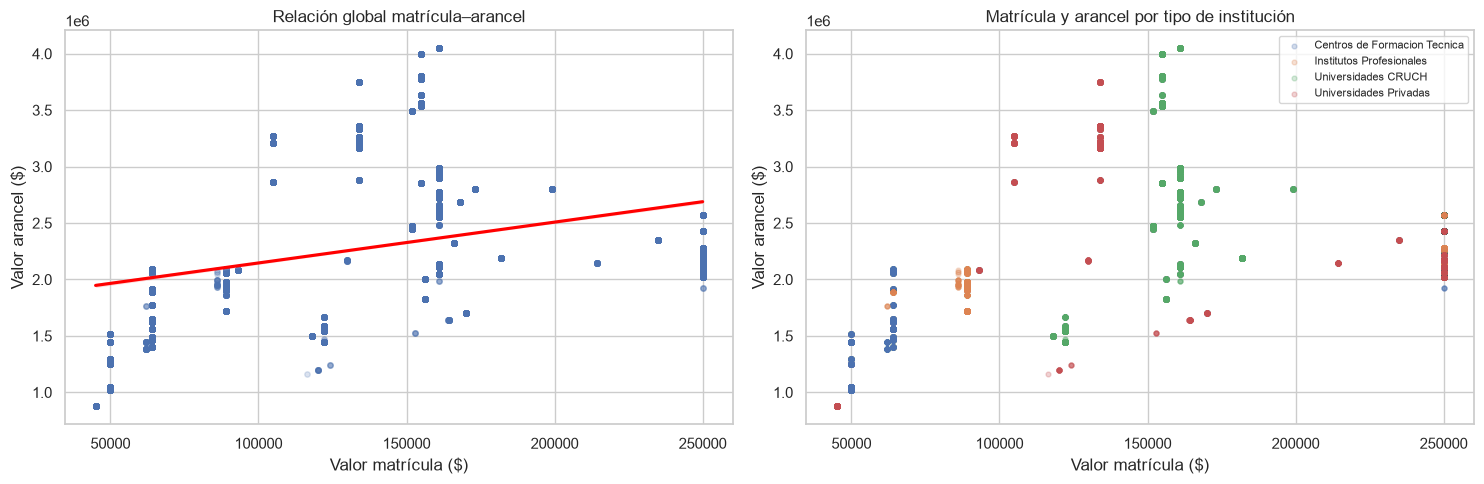

In [7]:
# Gráfico global y gráficos por tipo de institución con rectas de ajuste
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.regplot(data=df_clean, x='VALOR MATRICULA (PESOS)', y='VALOR ARANCEL (PESOS)',
            scatter_kws={'alpha': 0.20, 's': 15}, line_kws={'color': 'red'}, ax=axes[0])
axes[0].set_title('Relación global matrícula–arancel')
axes[0].set_xlabel('Valor matrícula ($)')
axes[0].set_ylabel('Valor arancel ($)')

for tipo, grupo in df_clean.groupby('TIPO DE INSTITUCION'):
    axes[1].scatter(grupo['VALOR MATRICULA (PESOS)'], grupo['VALOR ARANCEL (PESOS)'],
                    alpha=0.25, s=12, label=tipo)
axes[1].set_title('Matrícula y arancel por tipo de institución')
axes[1].set_xlabel('Valor matrícula ($)')
axes[1].set_ylabel('Valor arancel ($)')
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

### ¿Vale la pena estudiar todos los grupos?

In [8]:
# Resumen por grupo: tamaño, variabilidad y diversidad de valores de matrícula
resumen_grupos = df_clean.groupby('TIPO DE INSTITUCION').agg(
    n=('VALOR MATRICULA (PESOS)', 'size'),
    valores_distintos_matricula=('VALOR MATRICULA (PESOS)', 'nunique'),
    desviacion_estandar_matricula=('VALOR MATRICULA (PESOS)', 'std'),
    minimo_matricula=('VALOR MATRICULA (PESOS)', 'min'),
    maximo_matricula=('VALOR MATRICULA (PESOS)', 'max')
).sort_values('n', ascending=False)
display(resumen_grupos)
print('Criterio: se considera razonable estudiar grupos con tamaño suficiente y variabilidad;')
print('si hay pocos valores distintos, la correlación puede ser inestable o poco informativa.')

,n,valores_distintos_matricula,desviacion_estandar_matricula,minimo_matricula,maximo_matricula
TIPO DE INSTITUCION,,,,,
Universidades CRUCH,6528,11,"16,355.435",117990,199000
Institutos Profesionales,3118,5,"80,415.707",62000,250000
Centros de Formacion Tecnica,3115,4,"88,272.771",50000,250000
Universidades Privadas,2560,16,"62,333.250",45000,250000


Criterio: se considera razonable estudiar grupos con tamaño suficiente y variabilidad;
si hay pocos valores distintos, la correlación puede ser inestable o poco informativa.


#### Interpretación
En el conjunto completo se observa una **correlación positiva débil a moderada** entre matrícula y arancel (Pearson ≈ 0,325; Spearman ≈ 0,429). En términos generales, las matrículas más altas tienden a acompañarse de aranceles mayores, aunque la relación global no es especialmente fuerte. La diferencia entre ambos coeficientes sugiere que la asociación por rangos es algo más clara que la relación estrictamente lineal.

El análisis por tipo de institución cambia la conclusión: los Centros de Formación Técnica y los Institutos Profesionales presentan correlaciones positivas fuertes (Pearson cercanos a 0,77); las Universidades CRUCH muestran una relación positiva moderada (≈ 0,57), mientras que las Universidades Privadas presentan una correlación lineal prácticamente nula y levemente negativa (≈ -0,057). Por ello, **no corresponde generalizar la correlación global a todos los grupos**. La estructura de precios y la diversidad de matrículas varían entre tipos de institución.

Todos los grupos tienen miles de observaciones, por lo que su tamaño es suficiente. Sin embargo, los CFT y los IP presentan pocos valores distintos de matrícula (4 y 5, respectivamente), lo que debe considerarse al interpretar sus correlaciones: la matrícula toma valores discretos o concentrados y puede generar empates en los rangos.

## Ítem 1.2 Relación arancel–duración de la carrera

**Pregunta:** ¿Cuál es la relación entre arancel y duración? ¿Es verdad que mientras más larga la carrera, más cara? ¿Es igual en todas las áreas del conocimiento?

### Análisis global

n = 15,321
Pendiente = $232,888 por semestre
Intercepto = $483,471
R² = 0.597 (59.7%)
Correlación de Pearson = 0.773; p-valor = 0


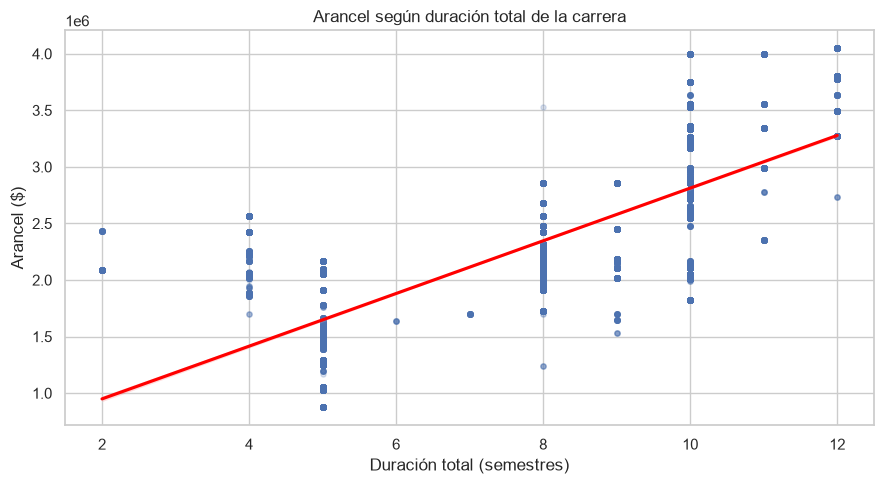

In [9]:
# Modelo lineal global: arancel como variable dependiente y duración como independiente
modelo_global = df_clean[['DURACION TOTAL CARRERA (SEMESTRES)', 'VALOR ARANCEL (PESOS)']].dropna()
X = modelo_global[['DURACION TOTAL CARRERA (SEMESTRES)']]
y = modelo_global['VALOR ARANCEL (PESOS)']
reg_global = LinearRegression().fit(X, y)
pred_global = reg_global.predict(X)
r2_global = r2_score(y, pred_global)
r_global, p_global = stats.pearsonr(X.iloc[:, 0], y)
print(f'n = {len(modelo_global):,}')
print(f'Pendiente = ${reg_global.coef_[0]:,.0f} por semestre')
print(f'Intercepto = ${reg_global.intercept_:,.0f}')
print(f'R² = {r2_global:.3f} ({r2_global*100:.1f}%)')
print(f'Correlación de Pearson = {r_global:.3f}; p-valor = {p_global:.3g}')

plt.figure(figsize=(9, 5))
sns.regplot(data=modelo_global, x='DURACION TOTAL CARRERA (SEMESTRES)', y='VALOR ARANCEL (PESOS)',
            scatter_kws={'alpha': 0.2, 's': 14}, line_kws={'color': 'red'})
plt.title('Arancel según duración total de la carrera')
plt.xlabel('Duración total (semestres)')
plt.ylabel('Arancel ($)')
plt.tight_layout()
plt.show()

### Análisis por área del conocimiento

In [10]:
# Modelos por área: se exige n >= 30 y más de un valor de duración
resultados_area = []
for area, grupo in df_clean.groupby('AREA CONOCIMIENTO'):
    datos = grupo[['DURACION TOTAL CARRERA (SEMESTRES)', 'VALOR ARANCEL (PESOS)']].dropna()
    if len(datos) >= 30 and datos['DURACION TOTAL CARRERA (SEMESTRES)'].nunique() > 1:
        X_area = datos[['DURACION TOTAL CARRERA (SEMESTRES)']]
        y_area = datos['VALOR ARANCEL (PESOS)']
        modelo = LinearRegression().fit(X_area, y_area)
        pred = modelo.predict(X_area)
        corr, pval = stats.pearsonr(X_area.iloc[:, 0], y_area)
        resultados_area.append({
            'Área': area, 'n': len(datos), 'Correlación': corr,
            'Pendiente ($/semestre)': modelo.coef_[0],
            'Intercepto ($)': modelo.intercept_, 'R²': r2_score(y_area, pred),
            'p-valor': pval
        })
tabla_area = pd.DataFrame(resultados_area).sort_values('n', ascending=False)
display(tabla_area)
print('Se excluyen áreas con menos de 30 registros o sin variación en duración,')
print('porque no permiten estimar una relación lineal suficientemente estable.')

,Área,n,Correlación,Pendiente ($/semestre),Intercepto ($),R²,p-valor
8,Tecnologia,4111,0.772,"182,703.392","913,262.346",0.596,0.000
0,Administracion y Comercio,3174,0.643,"165,445.917","936,889.216",0.414,0.000
7,Salud,2835,0.893,"315,885.201","-6,981.202",0.798,0.000
5,Educacion,2102,0.763,"160,064.978","667,019.702",0.583,0.000
3,Ciencias Sociales,1681,0.652,"227,721.095","474,570.444",0.425,0.000
4,Derecho,865,0.731,"279,145.751","250,513.499",0.535,0.000
1,Arte y Arquitectura,290,0.837,"147,444.638","1,315,438.470",0.700,0.000
6,Humanidades,156,1.000,"101,449.231","992,153.846",1.000,0.000
2,Ciencias Basicas,83,1.000,"187,400.000","607,000.000",1.000,0.000


Se excluyen áreas con menos de 30 registros o sin variación en duración,
porque no permiten estimar una relación lineal suficientemente estable.


### Visualización por área

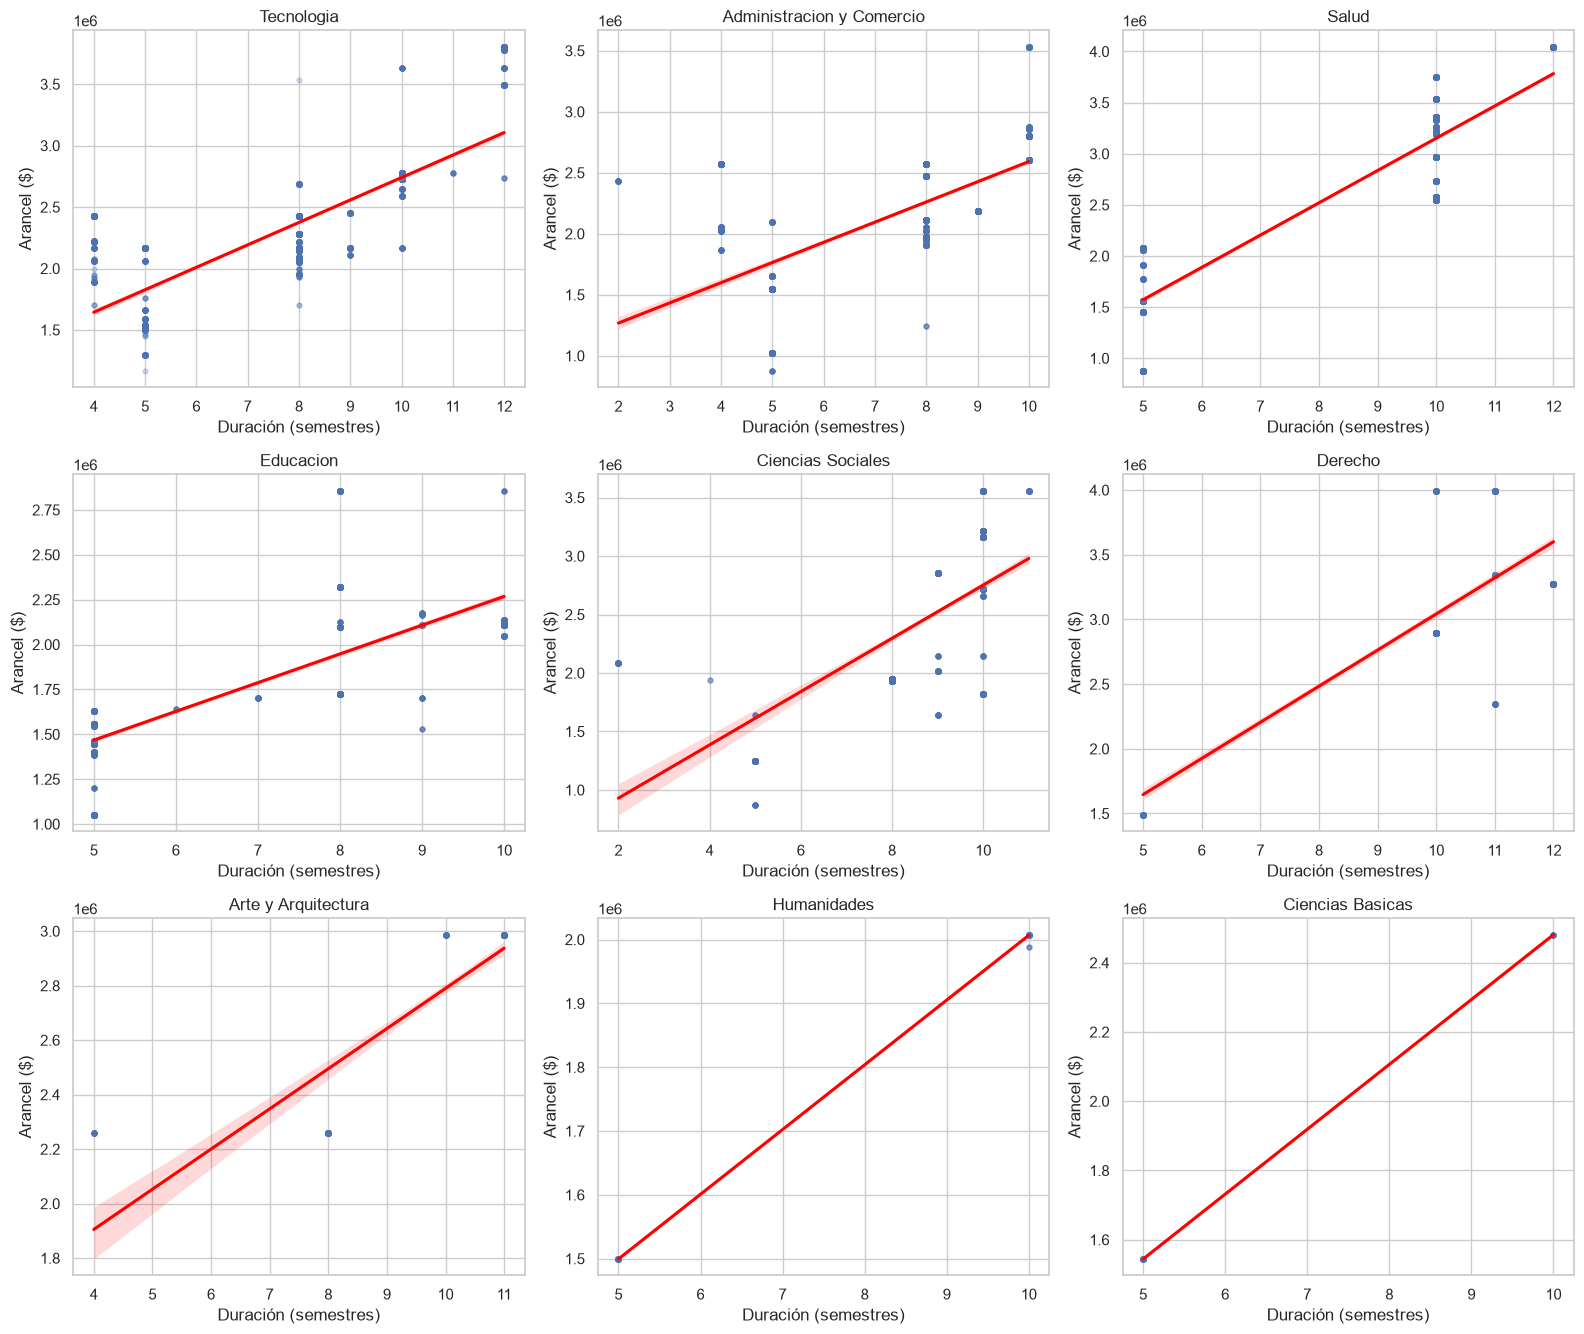

In [11]:
# Gráficos de dispersión y recta de regresión para cada área incluida
areas = tabla_area['Área'].tolist()
numero = len(areas)
filas = int(np.ceil(numero / 3))
fig, axes = plt.subplots(filas, 3, figsize=(16, 4.5 * filas), squeeze=False)
for ax, area in zip(axes.flat, areas):
    grupo = df_clean[df_clean['AREA CONOCIMIENTO'] == area]
    sns.regplot(data=grupo, x='DURACION TOTAL CARRERA (SEMESTRES)', y='VALOR ARANCEL (PESOS)',
                scatter_kws={'alpha': 0.25, 's': 12}, line_kws={'color': 'red'}, ax=ax)
    ax.set_title(area)
    ax.set_xlabel('Duración (semestres)')
    ax.set_ylabel('Arancel ($)')
for ax in axes.flat[numero:]:
    ax.set_visible(False)
plt.tight_layout()
plt.show()

### Diagnóstico del modelo

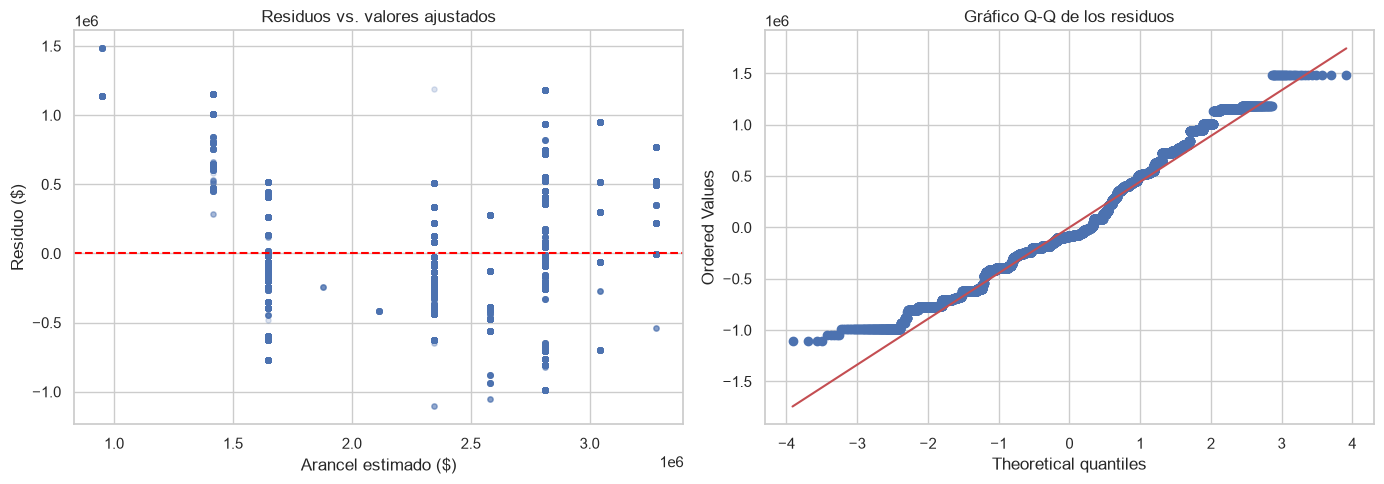

statsmodels no está instalado; revisar visualmente el gráfico de residuos.
Residuos con |z| > 3: 32
Porcentaje de residuos con |z| > 3: 0.21%


In [12]:
# Diagnóstico del modelo global mediante residuos
residuos = y - pred_global
residuos_estandarizados = (residuos - residuos.mean()) / residuos.std(ddof=1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].scatter(pred_global, residuos, alpha=0.2, s=14)
axes[0].axhline(0, color='red', linestyle='--')
axes[0].set_title('Residuos vs. valores ajustados')
axes[0].set_xlabel('Arancel estimado ($)')
axes[0].set_ylabel('Residuo ($)')

stats.probplot(residuos, dist='norm', plot=axes[1])
axes[1].set_title('Gráfico Q-Q de los residuos')
plt.tight_layout()
plt.show()

# Indicadores complementarios de heterocedasticidad y observaciones extremas
try:
    from statsmodels.stats.diagnostic import het_breuschpagan
    import statsmodels.api as sm
    prueba_bp = het_breuschpagan(residuos, sm.add_constant(X))
    print(f'Breusch-Pagan: LM={prueba_bp[0]:.2f}; p-valor={prueba_bp[1]:.3g}')
except ImportError:
    print('statsmodels no está instalado; revisar visualmente el gráfico de residuos.')
print(f'Residuos con |z| > 3: {(np.abs(residuos_estandarizados) > 3).sum()}')
print(f'Porcentaje de residuos con |z| > 3: {(np.abs(residuos_estandarizados) > 3).mean()*100:.2f}%')

#### Interpretación
A nivel global, la relación entre duración total y arancel es **positiva y relativamente fuerte** (r ≈ 0,773). El modelo lineal estimado es aproximadamente:

$$\widehat{Arancel}=483.471 + 232.888\times Duración$$

La pendiente indica que, en promedio, un semestre adicional de duración se asocia con un aumento estimado de alrededor de **$232.888** en el arancel. El coeficiente de determinación es cercano a 0,597: la duración explica aproximadamente el **59,7% de la variabilidad** observada en los aranceles del conjunto analizado.

La relación también es positiva en las áreas del conocimiento examinadas, pero su intensidad no es igual. Salud muestra una asociación particularmente alta (r ≈ 0,893; R² ≈ 0,798), mientras que Administración y Comercio y Ciencias Sociales presentan relaciones más moderadas (R² cercanos a 0,41 y 0,42). Por tanto, la afirmación “mientras más larga la carrera, más cara” se cumple como tendencia general, pero no permite predecir el arancel exacto ni implica que ocurra con la misma fuerza en todas las áreas.

El diagnóstico debe interpretarse con cautela: el gráfico de residuos y el Q-Q permiten revisar los supuestos, pero los aranceles presentan dispersión y posibles valores extremos. Si la prueba de Breusch–Pagan entrega un p-valor pequeño, existe evidencia de heterocedasticidad; en ese caso, los errores estándar clásicos y las predicciones del modelo deben tomarse con precaución. Además, un residuo extremo no demuestra por sí solo que una observación sea influyente: sería conveniente complementar con leverage y distancia de Cook si se requiere un diagnóstico más profundo.

---
# ÍTEM 2 · Modalidad y probabilidades

## Ítem 2.1 ¿Vuelta a la presencialidad o avance de formatos no presenciales?

**Pregunta:** ¿Se produjo una gran vuelta a la presencialidad o los formatos que incluyen no presencialidad han ganado terreno?

### Distribución global de modalidad

In [13]:
# Frecuencias absolutas y relativas de modalidad
frecuencia_modalidad = df_clean['MODALIDAD'].value_counts(dropna=False).to_frame('Frecuencia')
frecuencia_modalidad['Porcentaje'] = frecuencia_modalidad['Frecuencia'] / len(df_clean) * 100
display(frecuencia_modalidad)
print(f'Total de registros considerados: {len(df_clean):,}')

,Frecuencia,Porcentaje
MODALIDAD,,
Presencial,15062,98.310
Semipresencial,259,1.690


Total de registros considerados: 15,321


### Evolución por año de ingreso

In [14]:
# Tabla cruzada de año de ingreso y modalidad; porcentajes calculados dentro de cada año
tabla_anio_modalidad = pd.crosstab(df_clean['AÑO INGRESO'], df_clean['MODALIDAD'])
porcentaje_anio_modalidad = pd.crosstab(df_clean['AÑO INGRESO'], df_clean['MODALIDAD'], normalize='index') * 100
print('Frecuencias absolutas:')
display(tabla_anio_modalidad)
print('Porcentajes por año de ingreso:')
display(porcentaje_anio_modalidad.round(2))

Frecuencias absolutas:


MODALIDAD,Presencial,Semipresencial
AÑO INGRESO,,
1990,1,0
1997,1,0
2000,2,0
2001,1,0
2002,1,0
2003,2,0
2004,7,0
2005,1,0
2006,2,0


Porcentajes por año de ingreso:


MODALIDAD,Presencial,Semipresencial
AÑO INGRESO,,
1990,100.000,0.000
1997,100.000,0.000
2000,100.000,0.000
2001,100.000,0.000
2002,100.000,0.000
2003,100.000,0.000
2004,100.000,0.000
2005,100.000,0.000
2006,100.000,0.000


### Visualización

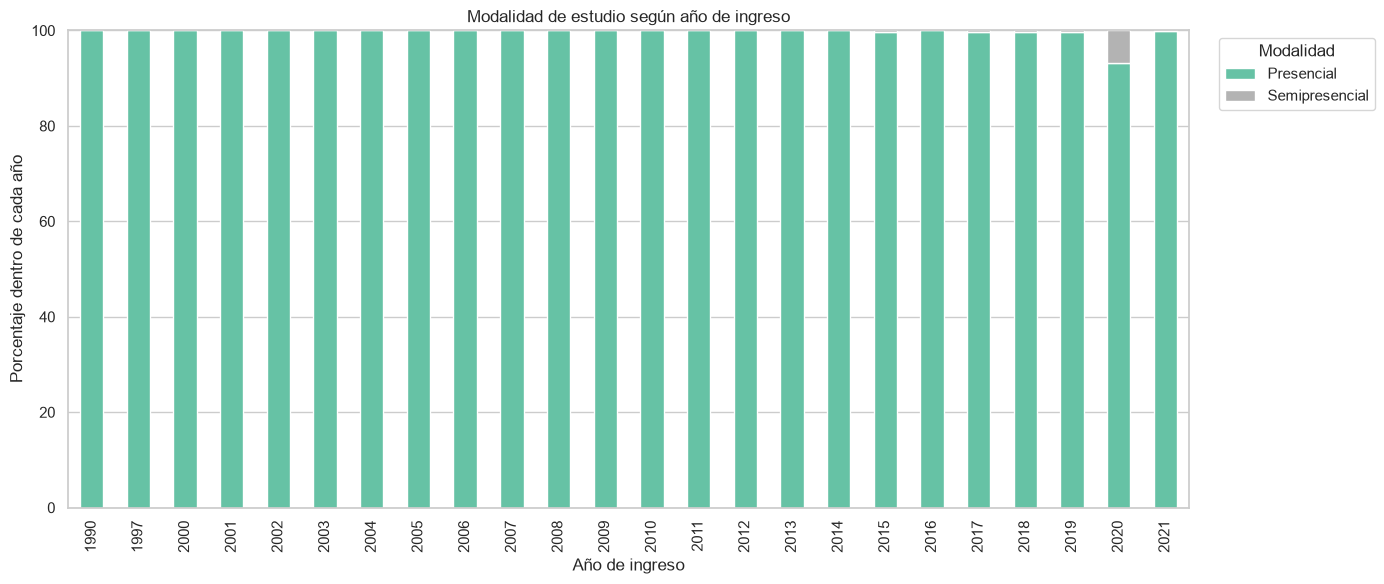

In [15]:
# Evolución de la composición de modalidad por año de ingreso
porcentaje_anio_modalidad.plot(kind='bar', stacked=True, figsize=(14, 6), colormap='Set2')
plt.title('Modalidad de estudio según año de ingreso')
plt.xlabel('Año de ingreso')
plt.ylabel('Porcentaje dentro de cada año')
plt.legend(title='Modalidad', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

#### Interpretación
La modalidad presencial predomina ampliamente en la base depurada. En el total de registros, aproximadamente **98,3% corresponde a modalidad presencial** y **1,7% a semipresencial**. Por lo tanto, los datos no muestran un desplazamiento generalizado hacia formatos que incorporan no presencialidad.

Al observar el año de ingreso, la modalidad presencial se mantiene como la opción dominante durante todo el período. Se aprecia un aumento puntual de la modalidad semipresencial entre quienes ingresaron en 2020 (cerca de 6,7%), pero esta participación vuelve a ser nula en 2021 dentro de los registros analizados. En años anteriores su presencia es muy reducida o inexistente.

En consecuencia, con esta base no se puede afirmar que haya ocurrido una gran vuelta a la presencialidad, porque la presencialidad ya era claramente predominante. Tampoco se observa una expansión sostenida de la modalidad semipresencial. Es importante recordar que el año corresponde al **año de ingreso** del estudiante y no necesariamente al año en que se registró la modalidad; por ello, la tabla describe cohortes de ingreso y no una serie anual de cambios de modalidad de estudiantes activos.

## Ítem 2.2 Tipo de institución con mayor uso de formatos no exclusivamente presenciales

**Pregunta:** ¿Qué tipo de institución emplea de mayor manera formatos no exclusivamente presenciales?

### Tabla cruzada tipo × modalidad

In [16]:
# Tabla cruzada tipo de institución × modalidad, con porcentajes por fila y tamaño de grupo
tabla_tipo_modalidad = pd.crosstab(df_clean['TIPO DE INSTITUCION'], df_clean['MODALIDAD'])
porcentaje_tipo_modalidad = pd.crosstab(df_clean['TIPO DE INSTITUCION'], df_clean['MODALIDAD'], normalize='index') * 100
resumen_tipo_modalidad = tabla_tipo_modalidad.copy()
resumen_tipo_modalidad['Total'] = resumen_tipo_modalidad.sum(axis=1)
print('Frecuencias absolutas:')
display(resumen_tipo_modalidad)
print('Porcentajes por tipo de institución:')
display(porcentaje_tipo_modalidad.round(2))

Frecuencias absolutas:


MODALIDAD,Presencial,Semipresencial,Total
TIPO DE INSTITUCION,,,
Centros de Formacion Tecnica,3115,0,3115
Institutos Profesionales,3115,3,3118
Universidades CRUCH,6528,0,6528
Universidades Privadas,2304,256,2560


Porcentajes por tipo de institución:


MODALIDAD,Presencial,Semipresencial
TIPO DE INSTITUCION,,
Centros de Formacion Tecnica,100.000,0.000
Institutos Profesionales,99.900,0.100
Universidades CRUCH,100.000,0.000
Universidades Privadas,90.000,10.000


### Visualización

,Matrículas no presenciales,Total,Porcentaje
TIPO DE INSTITUCION,,,
Centros de Formacion Tecnica,0,3115,0.000
Universidades CRUCH,0,6528,0.000
Institutos Profesionales,3,3118,0.096
Universidades Privadas,256,2560,10.000


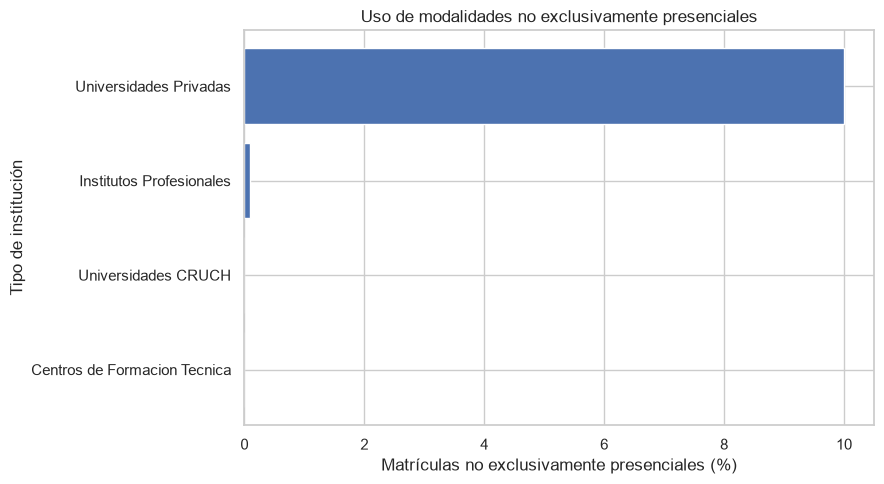

In [17]:
# Calcular el porcentaje de matrículas en modalidades que incluyen no presencialidad
modalidades_no_presenciales = [m for m in df_clean['MODALIDAD'].dropna().unique() if m != 'Presencial']
no_presencial = df_clean.assign(NO_EXCLUSIVAMENTE_PRESENCIAL=df_clean['MODALIDAD'].isin(modalidades_no_presenciales))
porcentaje_no_presencial = (no_presencial.groupby('TIPO DE INSTITUCION')['NO_EXCLUSIVAMENTE_PRESENCIAL']
                            .agg(['sum', 'count', 'mean']).rename(columns={'sum':'Matrículas no presenciales', 'count':'Total', 'mean':'Proporción'}))
porcentaje_no_presencial['Porcentaje'] = porcentaje_no_presencial['Proporción'] * 100
porcentaje_no_presencial = porcentaje_no_presencial.sort_values('Porcentaje')
display(porcentaje_no_presencial[['Matrículas no presenciales', 'Total', 'Porcentaje']])

plt.figure(figsize=(9, 5))
plt.barh(porcentaje_no_presencial.index, porcentaje_no_presencial['Porcentaje'])
plt.xlabel('Matrículas no exclusivamente presenciales (%)')
plt.ylabel('Tipo de institución')
plt.title('Uso de modalidades no exclusivamente presenciales')
plt.tight_layout()
plt.show()

### Asociación estadística (opcional)

In [18]:
# Prueba chi-cuadrado y V de Cramér para evaluar asociación entre tipo y modalidad
tabla_chi = pd.crosstab(df_clean['TIPO DE INSTITUCION'], df_clean['MODALIDAD'])
chi2, p_chi, grados_libertad, esperados = stats.chi2_contingency(tabla_chi)
n_total = tabla_chi.to_numpy().sum()
min_dimension = min(tabla_chi.shape)
v_cramer = np.sqrt(chi2 / (n_total * (min_dimension - 1)))
print(f'Chi-cuadrado = {chi2:.3f}')
print(f'Grados de libertad = {grados_libertad}')
print(f'p-valor = {p_chi:.3g}')
print(f'V de Cramér = {v_cramer:.3f}')
print('Frecuencias esperadas mínimas:', esperados.min())

Chi-cuadrado = 1277.114
Grados de libertad = 3
p-valor = 1.36e-276
V de Cramér = 0.289
Frecuencias esperadas mínimas: 43.27654852816396


#### Interpretación
Las Universidades Privadas son el tipo de institución que utiliza en mayor proporción formatos no exclusivamente presenciales: alrededor de **10,0%** de sus matrículas corresponde a modalidad semipresencial. En los Institutos Profesionales la proporción es cercana a 0,1%, mientras que en los Centros de Formación Técnica y las Universidades CRUCH los registros analizados son presenciales.

La prueba chi-cuadrado permite evaluar si tipo de institución y modalidad son independientes. El p-valor es extremadamente pequeño, por lo que se rechaza la hipótesis de independencia: existe asociación estadísticamente significativa entre ambas variables. El V de Cramér complementa el resultado e indica la intensidad de esa asociación; no obstante, la interpretación práctica debe considerar que la modalidad semipresencial es poco frecuente en el conjunto. La mayor proporción observada en Universidades Privadas es clara, pero no significa que la mayoría de sus estudiantes curse en esa modalidad: aproximadamente nueve de cada diez siguen siendo presenciales.

## Ítem 2.3 Probabilidades: área de Educación según género

**Pregunta:** ¿Cuál es la probabilidad de seleccionar, entre los estudiantes hombres, a uno del área de Educación? ¿Y entre las mujeres? ¿Hay discrepancia aparente? ¿Cómo se explica?

### Tabla de contingencia género × área

In [19]:
# Tabla de contingencia género × Educación / otras áreas
# En la base, el nombre de la categoría aparece como 'Educacion' (sin tilde).
df_genero_area = df_clean.dropna(subset=['GENERO', 'AREA CONOCIMIENTO']).copy()
df_genero_area['GRUPO_AREA'] = np.where(df_genero_area['AREA CONOCIMIENTO'].str.strip().str.casefold() == 'educacion',
                                        'Educación', 'Otras áreas')
tabla_genero_area = pd.crosstab(df_genero_area['GENERO'], df_genero_area['GRUPO_AREA'], margins=True)
display(tabla_genero_area)

GRUPO_AREA,Educación,Otras áreas,All
GENERO,,,
Femenino,1731,6921,8652
Masculino,371,6298,6669
All,2102,13219,15321


### Probabilidades condicionales

In [20]:
# Probabilidades condicionales: P(E|H), P(E|M) y probabilidad global P(E)
tabla_sin_totales = pd.crosstab(df_genero_area['GENERO'], df_genero_area['GRUPO_AREA'])
conteo_hombres = tabla_sin_totales.loc['Masculino'].sum()
conteo_mujeres = tabla_sin_totales.loc['Femenino'].sum()
conteo_educacion_h = tabla_sin_totales.loc['Masculino', 'Educación']
conteo_educacion_m = tabla_sin_totales.loc['Femenino', 'Educación']
conteo_educacion_total = tabla_sin_totales['Educación'].sum()

p_e_h = conteo_educacion_h / conteo_hombres
p_e_m = conteo_educacion_m / conteo_mujeres
p_e = conteo_educacion_total / tabla_sin_totales.to_numpy().sum()
print(f'P(E|H) = {conteo_educacion_h}/{conteo_hombres} = {p_e_h:.4f} ({p_e_h*100:.2f}%)')
print(f'P(E|M) = {conteo_educacion_m}/{conteo_mujeres} = {p_e_m:.4f} ({p_e_m*100:.2f}%)')
print(f'P(E) = {conteo_educacion_total}/{tabla_sin_totales.to_numpy().sum()} = {p_e:.4f} ({p_e*100:.2f}%)')

P(E|H) = 371/6669 = 0.0556 (5.56%)
P(E|M) = 1731/8652 = 0.2001 (20.01%)
P(E) = 2102/15321 = 0.1372 (13.72%)


### Comparación e independencia

In [21]:
# Comparación entre probabilidades y contraste de independencia género–área
print(f'Diferencia P(E|M) - P(E|H) = {(p_e_m-p_e_h)*100:.2f} puntos porcentuales')
print(f'Razón P(E|M) / P(E|H) = {p_e_m/p_e_h:.2f}')
chi2_genero, p_genero, gl_genero, esperados_genero = stats.chi2_contingency(tabla_sin_totales)
n_genero = tabla_sin_totales.to_numpy().sum()
v_genero = np.sqrt(chi2_genero / (n_genero * (min(tabla_sin_totales.shape)-1)))
print(f'Chi-cuadrado = {chi2_genero:.2f}; gl = {gl_genero}; p-valor = {p_genero:.3g}')
print(f'V de Cramér = {v_genero:.3f}')

Diferencia P(E|M) - P(E|H) = 14.44 puntos porcentuales
Razón P(E|M) / P(E|H) = 3.60
Chi-cuadrado = 662.52; gl = 1; p-valor = 4.22e-146
V de Cramér = 0.208


### Explicación de la discrepancia

,TIPO DE INSTITUCION,GENERO,sum,count,Porcentaje Educación
0,Centros de Formacion Tecnica,Femenino,640,1905,33.596
1,Centros de Formacion Tecnica,Masculino,99,1210,8.182
2,Institutos Profesionales,Femenino,131,1267,10.339
3,Institutos Profesionales,Masculino,15,1851,0.810
4,Universidades CRUCH,Femenino,777,3784,20.534
5,Universidades CRUCH,Masculino,246,2744,8.965
6,Universidades Privadas,Femenino,183,1696,10.790
7,Universidades Privadas,Masculino,11,864,1.273


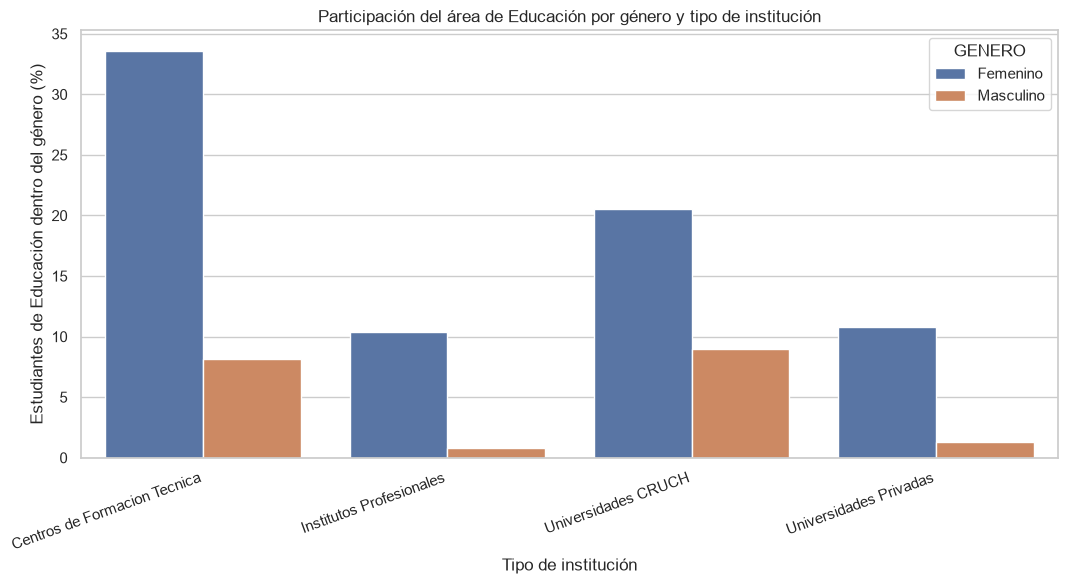

In [22]:
# Explorar la proporción de Educación por género dentro de cada tipo de institución
composicion_genero_tipo = (df_genero_area.assign(ES_EDUCACION=df_genero_area['GRUPO_AREA'].eq('Educación'))
                           .groupby(['TIPO DE INSTITUCION', 'GENERO'])['ES_EDUCACION']
                           .agg(['sum', 'count', 'mean']).reset_index())
composicion_genero_tipo['Porcentaje Educación'] = composicion_genero_tipo['mean'] * 100
display(composicion_genero_tipo[['TIPO DE INSTITUCION', 'GENERO', 'sum', 'count', 'Porcentaje Educación']])

plt.figure(figsize=(11, 6))
sns.barplot(data=composicion_genero_tipo, x='TIPO DE INSTITUCION', y='Porcentaje Educación', hue='GENERO')
plt.title('Participación del área de Educación por género y tipo de institución')
plt.xlabel('Tipo de institución')
plt.ylabel('Estudiantes de Educación dentro del género (%)')
plt.xticks(rotation=20, ha='right')
plt.tight_layout()
plt.show()

#### Interpretación
La probabilidad de seleccionar a un estudiante del área de Educación entre los hombres es aproximadamente **5,6%**; entre las mujeres alcanza cerca de **20,0%**. La diferencia es de aproximadamente **14,4 puntos porcentuales**, y la probabilidad condicional para las mujeres es alrededor de **3,6 veces** la de los hombres. La probabilidad global de que un estudiante pertenezca al área de Educación es cercana a **13,7%**.

La prueba chi-cuadrado entrega un p-valor muy inferior a 0,05, por lo que se rechaza la hipótesis de independencia entre género y pertenencia al área de Educación. La asociación es estadísticamente significativa y el V de Cramér permite cuantificar su intensidad (en este caso, pequeña a moderada). Esto respalda que la discrepancia observada no parece deberse solamente al azar en esta muestra.

La composición por tipo de institución ayuda a contextualizar el resultado: en todos los tipos institucionales considerados, la proporción de estudiantes del área de Educación es mayor entre las mujeres que entre los hombres. La diferencia es especialmente visible en Centros de Formación Técnica y también aparece en Universidades CRUCH, Institutos Profesionales y Universidades Privadas. Por tanto, la discrepancia no se explica únicamente porque hombres y mujeres se distribuyan en distintos tipos de institución; también existe una diferencia de participación por género dentro de cada tipo. Estos resultados describen asociaciones y no permiten concluir que el género cause la elección del área.